# Comparison to Analytic Solution

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import scipy as sc
import matplotlib.pyplot as plt
from matplotlib.ticker import Locator, MaxNLocator
from matplotlib.colors import LogNorm, to_rgb
from matplotlib import colormaps
from tqdm import tqdm

sys.path.append("../utils")
from myUtils import (calc_delta_benefit, calc_critical_treatment_threshold,
                     predict_ct_ttp, predict_atx_ttp, predict_at_threshold_ttp)
from plotUtils import PlotDrug, PlotSimulation, convert_to_rgb_grayscale
from odeModels import LotkaVolterraModel

In [2]:
# Defaults for plotting
plt.style.use(["classic", "../paper_figures/paper.mplstyle"])
plt.rcParams['font.size'] = '18'

colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'DRL_Monthly':'#66419e'}

/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_83036/884701199.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_xticklabels([''] + list(colors.keys()));


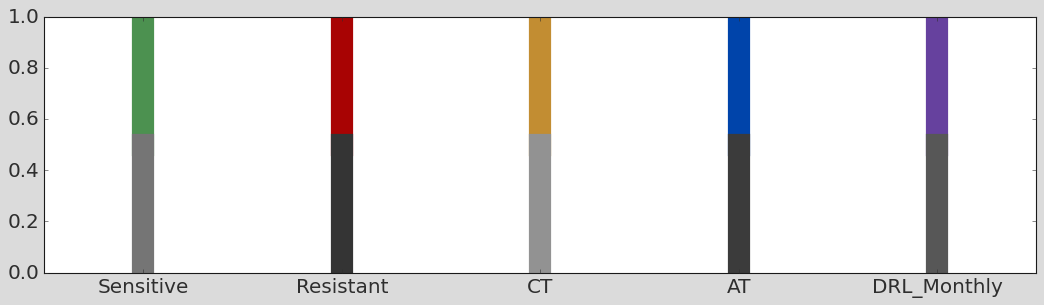

In [3]:
# Defaults for plotting
colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'DRL_Monthly':'#66419e'}

fig, ax = plt.subplots(1, 1, figsize=(16, 4))
for i, col in enumerate(colors.values()):
    plt.axvline(i+1, 0.5, 1, color = col, linewidth=20)
    plt.axvline(i+1, 0, 0.5, color = convert_to_rgb_grayscale(col), linewidth=20)
plt.xlim(0.5, len(colors.values()) + 0.5)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.gca().set_xticklabels([''] + list(colors.keys()));

In [4]:
file_path = os.path.dirname(os.path.abspath("__file__"))

out_dir = os.path.join(os.pardir, "patients", "Bruchovsky_et_al", "Prog_fits")

In [5]:
def Plot_method(df, legend=False, drug_label="Drug Concentration",
         ax=None, linewidth=5, drug_color = 'k', colors = None, **kwargs):
    if ax is None: fig, ax = plt.subplots(1, 1)
    linestyles = ['-', '--', '--']
    for i, var in enumerate(["TumourSize", 'S', 'R']):
        ax.plot(df['Time'], df[var], linewidth=linewidth, linestyle=linestyles[i], color=colors[var], **kwargs)

    PlotDrug(df, ax, drug_color, plotDrugAsBar = True, currDrugBarPosition = 1.25)

    # Format the plot
    ax.set_title(kwargs.get('title', ''))
    ax.yaxis.get_major_ticks()[-1].set_visible(False); ax.tick_params(right = False, top = False)

## Patient Datasets

In [6]:
# Load the data
df = pd.read_csv("patient_fits/full_history_params.csv")
trunc_df = pd.read_csv("patient_fits/first_cycle_params.csv")

patientIds = pd.merge(df[['PatientId']], trunc_df[['PatientId']], 
                      on='PatientId')['PatientId'].unique()

n = len(df['PatientId'].unique())
cols = [colormaps['tab10'](i/n) for i in range(n)]
markers = ['v', 's', 'X', 'P', 'o', '*', 'd',]

## TTP Prediction

In [7]:
import math

def calc_threshold_benefit(ave_n, **kwargs):
    params = kwargs
    return calc_delta_benefit(kappa=(ave_n / params['K']), **params)

def predict_at50_ttp_simp(**kwargs):
    # Simplified version that doesn't account for overshooting
    params = kwargs
    n_crit = params['n0']/2
    ave_n = (n_crit +  params['n0']) / 2
    benefit = calc_threshold_benefit(ave_n, **params)
    ct_ttp = predict_ct_ttp(**params)
    return ct_ttp * (1 + benefit)

def predict_at_threshold_ttp_simp(n_crit, **kwargs):
    # Simplified version that doesn't account for overshooting
    params = kwargs
    benefit = calc_delta_benefit(kappa=n_crit / params['K'], **params)
    ct_ttp = predict_ct_ttp(**params)
    return ct_ttp * (1 + benefit)

In [8]:
# Generate a table with patient id, predicted AT TTP
TTP_data = []
param_sets = [df]

for patientId in tqdm(patientIds):
    param_set = df.loc[df.PatientId == patientId].iloc[0].to_dict()
    
    ct_perfect_preds = int(predict_ct_ttp(**param_set))
    at50_perfect_preds = int(predict_at50_ttp_simp(**param_set))
    atx_overshoot_preds = int(predict_atx_ttp(30, **param_set))
    ncrit_perfect_preds = int(predict_at_threshold_ttp_simp(param_set['n0'], **param_set))
    ncrit_overshoot_preds = int(predict_at_threshold_ttp(30, **param_set)) 
    
    
    TTP_data.append([patientId, ct_perfect_preds, at50_perfect_preds, atx_overshoot_preds, 
                     ncrit_perfect_preds, ncrit_overshoot_preds])

at_ttp_df = pd.DataFrame(TTP_data, columns=['PatientId', 'CT_Perfect', 'AT50_Perfect', 'ATX_Overshoot',
                                                   'AT_NCrit_Perfect', 'AT_NCRIT_Overshoot'])
print(at_ttp_df)

100%|██████████| 5/5 [00:00<00:00, 1338.66it/s]

   PatientId  CT_Perfect  AT50_Perfect  ATX_Overshoot  AT_NCrit_Perfect  \
0         12         810           927            966               974   
1         20        1186          2132           2988              2905   
2         25        1063          1771           2125              2276   
3         78        1026          2179           3165              3481   
4         85         649          1019           1054              1258   

   AT_NCRIT_Overshoot  
0                 953  
1                3336  
2                2279  
3                4249  
4                1031  


1it [00:00,  2.02it/s]

Patient 12: Diff of -23 days (-2.76%)


2it [00:00,  2.15it/s]

Patient 85: Diff of -20 days (-2.99%)


3it [00:01,  2.20it/s]

Patient 25: Diff of -37 days (-3.36%)


4it [00:01,  2.16it/s]

Patient 20: Diff of -60 days (-4.82%)


5it [00:02,  2.14it/s]

Patient 78: Diff of -46 days (-4.29%)
Mean absolute error: 3.64 %


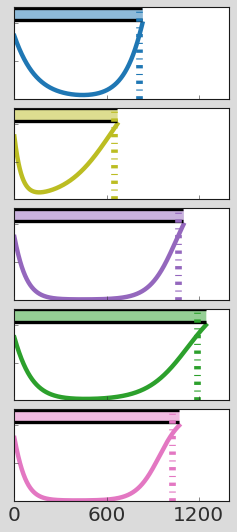

In [9]:
# Perfect CT

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(5, 1, figsize=(4, 7), sharex=True)

at_ttp_df = at_ttp_df.sort_values(by='AT_NCRIT_Overshoot')
ct_ttp_errors = []

for i, patientId in tqdm(enumerate(at_ttp_df['PatientId'])):
    params = df[df.PatientId == patientId].iloc[0].to_dict()
    model = LotkaVolterraModel(); model.SetParams(**params)
    model.Simulate([[0, 3000, 1]]); model.CleanData()
    
    patient_index = np.where(patientIds == patientId)[0][0]
    palette = {'TumourSize': cols[patient_index], 'S': None, 'R': None}
    
    PlotSimulation(model.resultsDf, ax=ax[i], colors=palette, linewidth=4, plot_subpops=False, 
                   drug_col=cols[patient_index], prog_line=False)
    ax[i].set_yticks(ax[i].get_yticks()[::3]); ax[i].set_yticklabels([])
    
    prediction = at_ttp_df.loc[at_ttp_df['PatientId'] == patientId]['CT_Perfect'].values[0]
    ax[i].axvline(prediction, color=cols[patient_index], linestyle='-.', linewidth=6)
    ax[i].set_ylim(0, 1.46); 
    
    error = (prediction - model.resultsDf.Time.max()) / model.resultsDf.Time.max() * 100
    ct_ttp_errors.append(error)
    print(f"Patient {patientId}: Diff of {int(prediction - model.resultsDf.Time.max())} days" + 
          f" ({error:.2f}%)")

print(f"Mean absolute error: {np.mean(np.abs(ct_ttp_errors)):.2f} %")
ax[-1].set_xticks(ax[-1].get_xticks()[::3])   
fig.subplots_adjust(hspace=0.1)
plt.savefig("figures/SI_ct_predictions.pdf", dpi=300, bbox_inches='tight')


The discrepancy between the true and estimated values here is due to competitive supression of the resistant population while the sensitive population is non-negligible. We can demonstrate this by predicting the TTP for alternate profiles with a raised carrying capacity (to mimic a zero-competition scenario), where the predictions (below) are exact. 
It may be possible to replicate this accuracy in competitive scenarios by first solving the sensitive population (under the much more reasonable assumption that the resistant population is negligible), then plugging the resultant exponential decay equation into the equation for R(t).

1it [00:00,  2.21it/s]

Patient 85: Diff of 0 days (-0.10%)


2it [00:00,  2.13it/s]

Patient 12: Diff of 0 days (-0.05%)


3it [00:01,  2.07it/s]

Patient 78: Diff of 0 days (0.03%)


4it [00:01,  2.14it/s]

Patient 25: Diff of 0 days (-0.05%)


5it [00:02,  2.15it/s]

Patient 20: Diff of 0 days (-0.02%)


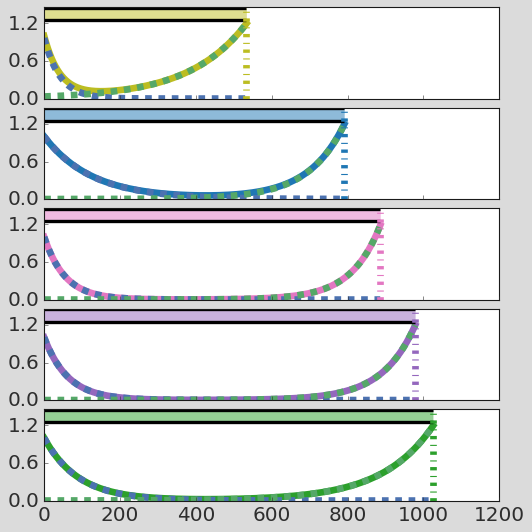

In [10]:
# Perfect CT -This would be perfect without supression of R at the start. But we could probably solve with this, as it is just exponential decay??
# Test this by raising K so there is no competition
# Have already tested that S is negligible at the end so doesn't affect dynamics there


plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(5, 1, figsize=(7, 7), sharex=True)

at_ttp_df = at_ttp_df.sort_values(by='CT_Perfect')

for i, patientId in tqdm(enumerate(at_ttp_df['PatientId'])):
    params = df[df.PatientId == patientId].iloc[0].to_dict()
    params['K'] = 100
    model = LotkaVolterraModel(); model.SetParams(**params)
    model.Simulate([[0, 3000, 1]]); model.CleanData()
    
    patient_index = np.where(patientIds == patientId)[0][0]
    palette = {'TumourSize': cols[patient_index], 'S': None, 'R': None}
    
    PlotSimulation(model.resultsDf, ax=ax[i], colors=palette, linewidth=6, plot_subpops=True, 
                   drug_col=cols[patient_index], prog_line=False)
    ax[i].set_yticks(ax[i].get_yticks()[::3])
    
    prediction = predict_ct_ttp(**params)  # Need to recalculate this
    ax[i].axvline(prediction, color=cols[patient_index], linestyle='-.', linewidth=6)
    ax[i].set_ylim(0, 1.46)
    
    print(f"Patient {patientId}: Diff of {int(prediction - model.resultsDf.Time.max())} days" + 
          f" ({(prediction - model.resultsDf.Time.max()) / model.resultsDf.Time.max() * 100:.2f}%)")

# ax[-1].set_xlim(0, 2024)    
fig.subplots_adjust(hspace=0.1)
# plt.savefig("figures/SI_at_predictions.pdf", dpi=300, bbox_inches='tight')


1it [00:00,  1.71it/s]

Patient 85: Diff of 0 days (-0.05%)


2it [00:01,  1.66it/s]

Patient 12: Diff of 0 days (-0.11%)


3it [00:01,  1.64it/s]

Patient 78: Diff of 0 days (-0.08%)


4it [00:02,  1.66it/s]

Patient 25: Diff of 0 days (-0.03%)


5it [00:03,  1.64it/s]

Patient 20: Diff of 0 days (-0.03%)


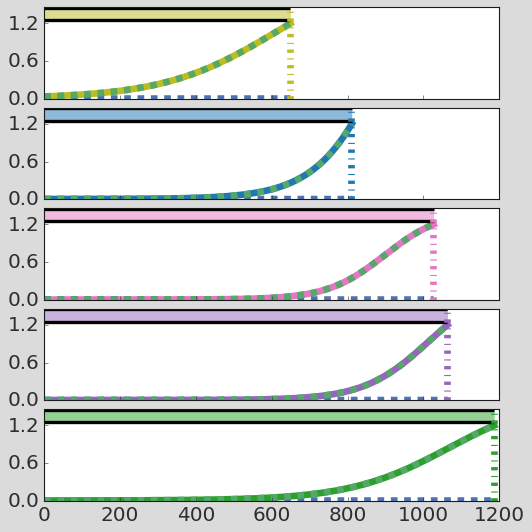

In [11]:
# Full resistant tumor

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(5, 1, figsize=(7, 7), sharex=True)

at_ttp_df = at_ttp_df.sort_values(by='CT_Perfect')

for i, patientId in tqdm(enumerate(at_ttp_df['PatientId'])):
    params = df[df.PatientId == patientId].iloc[0].to_dict()
    params['S0'] = 0
    model = LotkaVolterraModel(); model.SetParams(**params)
    model.Simulate([[0, 3000, 1]]); 
    model.resultsDf = model.resultsDf[model.resultsDf.TumourSize < params['n0'] * 1.2]
    
    model.resultsDf[['TumourSize', 'R', 'S']] /= params['n0']
    
    patient_index = np.where(patientIds == patientId)[0][0]
    palette = {'TumourSize': cols[patient_index], 'S': None, 'R': None}
    
    PlotSimulation(model.resultsDf, ax=ax[i], colors=palette, linewidth=6, plot_subpops=True, 
                   drug_col=cols[patient_index], prog_line=False)
    ax[i].set_yticks(ax[i].get_yticks()[::3])
    
    prediction = at_ttp_df.loc[at_ttp_df['PatientId'] == patientId]['CT_Perfect'].values[0]
    ax[i].axvline(prediction, color=cols[patient_index], linestyle='-.', linewidth=6)
    ax[i].set_ylim(0, 1.46)
    
    print(f"Patient {patientId}: Diff of {int(prediction - model.resultsDf.Time.max())} days" + 
          f" ({(prediction - model.resultsDf.Time.max()) / model.resultsDf.Time.max() * 100:.2f}%)")

# ax[-1].set_xlim(0, 2024)    
fig.subplots_adjust(hspace=0.1)
# plt.savefig("figures/SI_at_predictions.pdf", dpi=300, bbox_inches='tight')


We can quantify the impact of competition on the resistant TTP analytically...

In [12]:
from scipy.special import lambertw

def predict_time_discrepancy(rS, dS, rR, dR, dD, S0, R0, n0, K, **kwargs):
    a = rS * (1 - dD) - dS
    pre_factor = (- a**2 * S0) / (K * (rR - dR))
    power_term = (2) ** (a / (rR - dR))
    return (-1 / a) * lambertw(pre_factor * power_term).real

In [13]:
def evaluate_progression_limit(t, rS, dS, rR, dR, dD, S0, R0, n0, K, **kwargs):
    a = rS * (1 - dD) - dS
    exponent = (rR - dR) * t - (S0 * a / K) * np.exp(a * t)
    return R0 * np.exp(exponent)

In [14]:
for i, patientId in tqdm(enumerate(at_ttp_df['PatientId'])):
    params = df[df.PatientId == patientId].iloc[0].to_dict()
    time_discrepancy = predict_time_discrepancy(**params)
    # print(f"Patient {patientId}: Time discrepancy of {time_discrepancy} days")
    
    base_time = np.log(2) / (params['rR'] - params['dR'])
    print(f"Patient {patientId}: Time discrepancy of {time_discrepancy:.2g} days (relative to base time of {base_time:.0f} days, "
          +f"giving an error of {100 * time_discrepancy / base_time:.2g}%)")
    uncorrected_progression_limit = evaluate_progression_limit(base_time, **params)
    corrected_progression_limit = evaluate_progression_limit(base_time + time_discrepancy, **params)

    print(f"  Uncorrected Progression Limit: {uncorrected_progression_limit:.8f}, Corrected Progression Limit: {corrected_progression_limit:.8f}, "
          + f"True Progression Limit: {5 * params['R0']:.8f}")  # Check these match

5it [00:00, 4690.57it/s]

Patient 85: Time discrepancy of -0.057 days (relative to base time of 102 days, giving an error of -0.056%)
  Uncorrected Progression Limit: 0.06452517, Corrected Progression Limit: 0.06450009, True Progression Limit: 0.16125021
Patient 12: Time discrepancy of -0.067 days (relative to base time of 65 days, giving an error of -0.1%)
  Uncorrected Progression Limit: 0.00041097, Corrected Progression Limit: 0.00041068, True Progression Limit: 0.00102671
Patient 78: Time discrepancy of -0.25 days (relative to base time of 52 days, giving an error of -0.47%)
  Uncorrected Progression Limit: 0.00001644, Corrected Progression Limit: 0.00001638, True Progression Limit: 0.00004096
Patient 25: Time discrepancy of -0.19 days (relative to base time of 59 days, giving an error of -0.31%)
  Uncorrected Progression Limit: 0.00002738, Corrected Progression Limit: 0.00002732, True Progression Limit: 0.00006830
Patient 20: Time discrepancy of -0.2 days (relative to base time of 92 days, giving an error 

1it [00:01,  1.03s/it]

Patient 12: Diff of 0 days (0.01%) [True: 751; Predicted: 751]


2it [00:02,  1.01s/it]

Patient 85: Diff of 17 days (3.25%) [True: 532; Predicted: 549]


3it [00:03,  1.12s/it]

Patient 25: Diff of 0 days (0.00%) [True: 1808; Predicted: 1808]


4it [00:04,  1.21s/it]

Patient 20: Diff of 1 days (0.08%) [True: 2033; Predicted: 2035]


5it [00:06,  1.23s/it]

Patient 78: Diff of 0 days (0.00%) [True: 2708; Predicted: 2709]


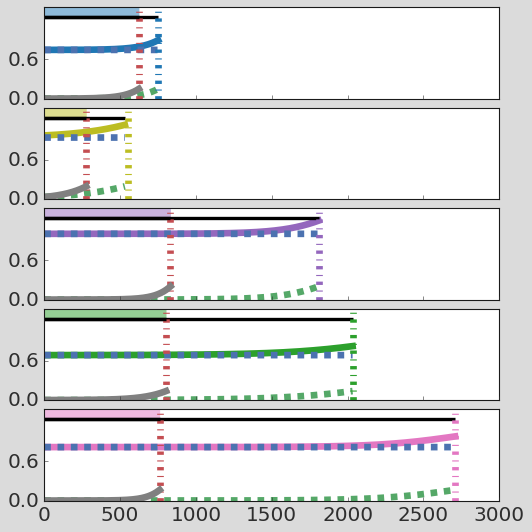

In [15]:
# First consider a simplified case where we fix the sensitive population, and compare it to S=0
# This is directly equivalent to the doubling time example, but we consider growth to progression.
# Because progression occurs at 1.2n0, and S = n0 (approx), this requires R = 0.2n0 
# Instead of the doubling time, we therefore consider the time to grow to this size.

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(5, 1, figsize=(7, 7), sharex=True)

at_ttp_df = at_ttp_df.sort_values(by='ATX_Overshoot')

for i, patientId in tqdm(enumerate(at_ttp_df['PatientId'])):
    params = df[df.PatientId == patientId].iloc[0].to_dict()
    params['rS'] = 0; params['dS'] = 0; params['dD'] = 0
    model = LotkaVolterraModel(); model.SetParams(**params)
    
    model.Simulate([[0, 3000, 0]]); 
    model.resultsDf = model.resultsDf[model.resultsDf.R < params['n0'] * 0.2]
    
    patient_index = np.where(patientIds == patientId)[0][0]
    palette = {'TumourSize': cols[patient_index], 'S': None, 'R': None}
    
    PlotSimulation(model.resultsDf, ax=ax[i], colors=palette, linewidth=6, plot_subpops=True, 
                   drug_col=cols[patient_index], prog_line=False)
    ax[i].set_yticks(ax[i].get_yticks()[::3])
    
    prediction = predict_at_threshold_ttp_simp(n_crit = params['n0'], upper = params['n0'] * 0.2,
                                               n_lim = params['n0']*0.2, **params)
    ax[i].axvline(prediction, color=cols[patient_index], linestyle='-.', linewidth=6)
    ax[i].set_ylim(0, 1.46)
    
    ct_prediction = int(predict_ct_ttp(n_lim = params['n0'] *0.2, **params))
    ax[i].axvline(ct_prediction, color='r', linestyle='-.', linewidth=6)
    
    if True:
        params['S0'] = 0
        model2 = LotkaVolterraModel(); model2.SetParams(**params)
        model2.Simulate([[0, 3000, 1]]); 
        model2.resultsDf = model2.resultsDf[model2.resultsDf.R < params['n0'] * 0.2]
        patient_index = np.where(patientIds == patientId)[0][0]
        palette = {'TumourSize': 'gray', 'S': None, 'R': None}

        PlotSimulation(model2.resultsDf, ax=ax[i], colors=palette, linewidth=6, plot_subpops=False, 
                        drug_col=cols[patient_index], prog_line=False)
    
    print(f"Patient {patientId}: Diff of {int(prediction - model.resultsDf.Time.max())} days" + 
          f" ({(prediction - model.resultsDf.Time.max()) / model.resultsDf.Time.max() * 100:.2f}%)" +
          f" [True: {model.resultsDf.Time.max():.0f}; Predicted: {prediction:.0f}]")

# ax[-1].set_xlim(0, 2024)    
fig.subplots_adjust(hspace=0.1)
# plt.savefig("figures/SI_at_predictions.pdf", dpi=300, bbox_inches='tight')


This demonstrates this approach's accuracy on a simplified case, where we hold the sensitive population constant artificially. Can we replicate it on the real threshold case?

Consider treatment where we set a threshold around the initial tumor size, and re-evaluate treatment every day. This is the most idealistic 'real' treatment situation.

1it [00:02,  2.86s/it]

Patient 12: Diff of -30 days (-3.31%) [True: 914; Predicted: 884]


2it [00:06,  3.56s/it]

Patient 85: Diff of -64 days (-6.41%) [True: 1002; Predicted: 938]


3it [00:23,  9.53s/it]

Patient 25: Diff of -11 days (-0.55%) [True: 2075; Predicted: 2064]


4it [00:45, 14.46s/it]

Patient 20: Diff of 12 days (0.52%) [True: 2494; Predicted: 2507]


5it [01:02, 12.49s/it]

Patient 78: Diff of 119 days (4.00%) [True: 2992; Predicted: 3112]
Mean absolute error: 2.96 %


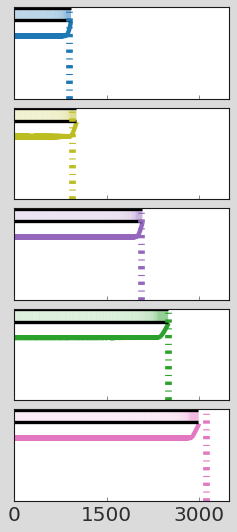

In [16]:
# Note that the resistant population now needs to grow beyond 0.2n0 to reach progression, 
# This is because treatment depletes the sensitive population to maintain a constant overall tumor size.
# In reality the sensitive population is not eliminated (and also does not provide consistent supression as it shrinks)
# To account for this, we assume that the resistant population must grow to 0.6n (ie final tumor is half resistant)


plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(5, 1, figsize=(4, 7), sharex=True)

at_ttp_df = at_ttp_df.sort_values(by='ATX_Overshoot')
threshold_errors = []

for i, patientId in tqdm(enumerate(at_ttp_df['PatientId'])):
    params = df[df.PatientId == patientId].iloc[0].to_dict()
    model = LotkaVolterraModel(); model.SetParams(**params)
    
    model.Simulate_AT(atThreshold = 1, atMethod='Threshold',
                intervalLength=1, t_end=6000, refSize = params['n0'])
    model.CleanData()
    
    patient_index = np.where(patientIds == patientId)[0][0]
    palette = {'TumourSize': cols[patient_index], 'S': None, 'R': None}
    
    PlotSimulation(model.resultsDf, ax=ax[i], colors=palette, linewidth=4, plot_subpops=False, 
                   drug_col=cols[patient_index], prog_line=False)
    ax[i].set_yticks([])
    
    prediction = predict_at_threshold_ttp_simp(n_crit=params['n0'], upper = params['n0'] * 0.2, 
                                               n_lim = params['n0']*0.6, **params)
    ax[i].axvline(prediction, color=cols[patient_index], linestyle='-.', linewidth=6)
    ax[i].set_ylim(0, 1.46)
    
    error = (prediction - model.resultsDf.Time.max()) / model.resultsDf.Time.max() * 100
    threshold_errors.append(error)
    print(f"Patient {patientId}: Diff of {int(prediction - model.resultsDf.Time.max())} days" + 
          f" ({error:.2f}%)" +
          f" [True: {model.resultsDf.Time.max():.0f}; Predicted: {prediction:.0f}]")

print(f"Mean absolute error: {np.mean(np.abs(threshold_errors)):.2f} %")
ax[-1].set_xticks(ax[-1].get_xticks()[::3])   
fig.subplots_adjust(hspace=0.1)
plt.savefig("figures/SI_threshold_predictions.pdf", dpi=300, bbox_inches='tight')


Can we now extend this to more complicated treatment scenarios???

In [17]:
def predict_at50_ttp_simp(**kwargs):
    # Simplified version that doesn't account for overshooting
    params = kwargs
    n_crit = params['n0']/2
    ave_n = (n_crit + params['n0'])/2
    benefit = calc_threshold_benefit(ave_n, **params)
    ct_ttp = predict_ct_ttp(**params)
    return ct_ttp * (1 + benefit)

1it [00:02,  2.08s/it]

Patient 12: Diff of -46 days (-5.19%)


2it [00:03,  1.91s/it]

Patient 85: Diff of -77 days (-9.30%)


3it [00:09,  3.51s/it]

Patient 25: Diff of -22 days (-1.41%)


4it [00:16,  4.95s/it]

Patient 20: Diff of -56 days (-3.01%)


5it [00:23,  4.68s/it]

Patient 78: Diff of 10 days (0.54%)
Mean absolute error: 3.89 %


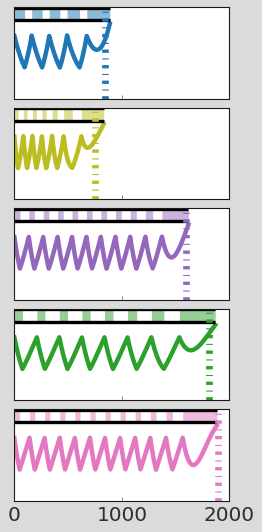

In [18]:
# Perfect AT50, no overshooting

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(5, 1, figsize=(4, 7), sharex=True)

at_ttp_df = at_ttp_df.sort_values(by='AT_NCRIT_Overshoot')
perfect_at_errors = []

for i, patientId in tqdm(enumerate(at_ttp_df['PatientId'])):
    params = df[df.PatientId == patientId].iloc[0].to_dict()
    model = LotkaVolterraModel(); model.SetParams(**params)
    
    model.Simulate_AT(atThreshold=0.5, atMethod='Zhang',
                intervalLength=1, t_end=6000, refSize = params['n0'])
    model.CleanData()
    
    patient_index = np.where(patientIds == patientId)[0][0]
    palette = {'TumourSize': cols[patient_index], 'S': None, 'R': None}
    
    PlotSimulation(model.resultsDf, ax=ax[i], colors=palette, linewidth=4, plot_subpops=False, 
                   drug_col=cols[patient_index], prog_line=False)
    ax[i].set_yticks([])
    
    prediction = predict_at50_ttp_simp(upper = params['n0'] * 0.2, 
                                               n_lim = params['n0']*0.6, **params)
    ax[i].axvline(prediction, color=cols[patient_index], linestyle='-.', linewidth=6)
    ax[i].set_ylim(0, 1.46)
    
    error = (prediction - model.resultsDf.Time.max()) / model.resultsDf.Time.max() * 100
    perfect_at_errors.append(error)
    print(f"Patient {patientId}: Diff of {int(prediction - model.resultsDf.Time.max())} days" + 
          f" ({error:.2f}%)")

print(f"Mean absolute error: {np.mean(np.abs(perfect_at_errors)):.2f} %")
ax[-1].set_xticks(ax[-1].get_xticks()[::2])   
fig.subplots_adjust(hspace=0.1)
plt.savefig("figures/SI_perfect_at_predictions.pdf", dpi=300, bbox_inches='tight')


Okay so this works on perfect threshold and ATX schedules. But can it account for the overshooting typical of discrete schedules?

1it [00:00,  3.08it/s]

Patient 12: Diff of -35 days (-3.92%)


2it [00:00,  3.72it/s]

Patient 85: Diff of 111 days (16.64%)


3it [00:01,  1.52it/s]

Patient 25: Diff of -26 days (-1.36%)


4it [00:03,  1.03it/s]

Patient 20: Diff of 32 days (1.27%)


5it [00:04,  1.05it/s]

Patient 78: Diff of -19 days (-0.68%)
Mean absolute error: 4.77 %


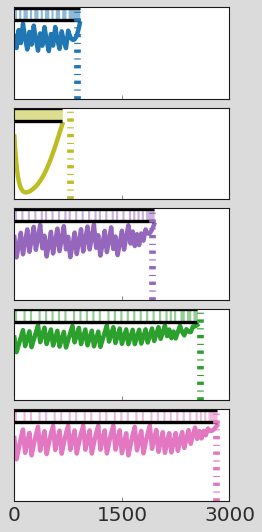

In [30]:
# Window ATX - Optimal threshold chosen for 30 days, with overshooting
tau = 30

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(5, 1, figsize=(4, 7), sharex=True)

at_ttp_df = at_ttp_df.sort_values(by='ATX_Overshoot')
imperfect_at_errors = []

for i, patientId in tqdm(enumerate(at_ttp_df['PatientId'])):
    params = df[df.PatientId == patientId].iloc[0].to_dict()
    model = LotkaVolterraModel(); model.SetParams(**params)
    
    threshold = calc_critical_treatment_threshold(tau, **params)
    if patientId == 85: threshold *= 0.1  # Scaling for biased threshold
    model.Simulate_AT(atThreshold = threshold / params['n0'], atMethod='Zhang',
                intervalLength=tau, t_end=6000, refSize = params['n0'])
    model.CleanData()
    
    patient_index = np.where(patientIds == patientId)[0][0]
    palette = {'TumourSize': cols[patient_index], 'S': None, 'R': None}
    
    PlotSimulation(model.resultsDf, ax=ax[i], colors=palette, linewidth=4, plot_subpops=False, 
                   drug_col=cols[patient_index], prog_line=False)
    ax[i].set_yticks([])
    
    prediction = predict_atx_ttp(tau=30, upper = params['n0'] * 0.2, 
                                 n_lim = params['n0']*0.6, **params)
    ax[i].axvline(prediction, color=cols[patient_index], linestyle='-.', linewidth=6)
    ax[i].set_ylim(0, 1.46)
    
    error = (prediction - model.resultsDf.Time.max()) / model.resultsDf.Time.max() * 100
    imperfect_at_errors.append(error)
    print(f"Patient {patientId}: Diff of {int(prediction - model.resultsDf.Time.max())} days" + 
          f" ({error:.2f}%)")

print(f"Mean absolute error: {np.mean(np.abs(imperfect_at_errors)):.2f} %")
ax[-1].set_xticks(ax[-1].get_xticks()[::3])   
fig.subplots_adjust(hspace=0.1)
plt.savefig("figures/SI_imperfect_at_predictions.pdf", dpi=300, bbox_inches='tight')


In [20]:
def calc_average_overshoot_var_zeta(tau, n_crit, zeta_fraction, **kwargs):
    # Arithmetic average
    params = kwargs
    a = params['rS'] * (1 - params['dD']) - params['dR']
    b = params['rS'] * (1 - params['dD']) / params['K']
    denom = b * n_crit - (b * n_crit - a) * np.exp(- a * tau)
    max_overshoot_pos = (a * n_crit) / denom
    return (n_crit - max_overshoot_pos) * zeta_fraction

def calc_atx_benefit_var_zeta(tau, zeta_fraction, **kwargs):
    """Calculate benefit of using an interval based optimal strategy 
    at a given time interval, relative to an unsuppressed population.
    Suppression is given by arithmetic mean of crit threshold and 
    progression limit, as the tumor oscillates between these two values.
    """
    params = kwargs
    n_crit = calc_critical_treatment_threshold(tau=tau, **params)
    n_overshoot = calc_average_overshoot_var_zeta(tau, n_crit, zeta_fraction=zeta_fraction, **params)
    ave_n = ((n_crit + 1.2 * params['n0'])/2 - n_overshoot)
    return calc_delta_benefit(kappa=(ave_n / params['K']), **params)

def predict_atx_ttp_var_zeta(tau, zeta_fraction, **kwargs):
    params = kwargs
    benefit = calc_atx_benefit_var_zeta(tau, zeta_fraction=zeta_fraction, **params)
    ct_ttp = predict_ct_ttp(**params)
    return ct_ttp * (1 + benefit)

In [ ]:
# Define the range of zeta fractions to test (0.0 to 1.0)
# 0.5 represents your current zeta/2 heuristic
zeta_fractions = np.linspace(0.0, 1.0, 21)
mean_absolute_errors = []

# Optional: To save compute time, pre-simulate the TTPs if you haven't already
# precomputed_ttps = {pid: get_simulated_ttp(pid) for pid in at_ttp_df['PatientId']}

for fraction in tqdm(zeta_fractions, desc="Testing Zeta Fractions"):
    imperfect_at_errors = []
    
    for patientId in at_ttp_df['PatientId']:
        params = df[df.PatientId == patientId].iloc[0].to_dict()
        
        # 1. Run the Digital Avatar Simulation (Ground Truth)
        model = LotkaVolterraModel()
        model.SetParams(**params)
        threshold = calc_critical_treatment_threshold(tau, **params)
        if patientId == 85: 
            continue  # Skip this patient as the threshold is biased and not relevant for this analysis
        
        model.Simulate_AT(atThreshold=threshold / params['n0'], atMethod='Zhang',
                          intervalLength=tau, t_end=6000, refSize=params['n0'])
        simulated_ttp = model.resultsDf.Time.max()
        
        # 2. Make the Analytical Prediction with the varying fraction
        prediction = predict_atx_ttp_var_zeta(tau=30, upper=params['n0'] * 0.2, 
                                     n_lim=params['n0']*0.6, 
                                     zeta_fraction=fraction, **params)
        
        # 3. Calculate absolute percentage error
        error = np.abs((prediction - simulated_ttp) / simulated_ttp) * 100
        imperfect_at_errors.append(error)
        
    mean_absolute_errors.append(np.mean(imperfect_at_errors))

Testing Zeta Fractions: 100%|██████████| 21/21 [01:31<00:00,  4.34s/it]


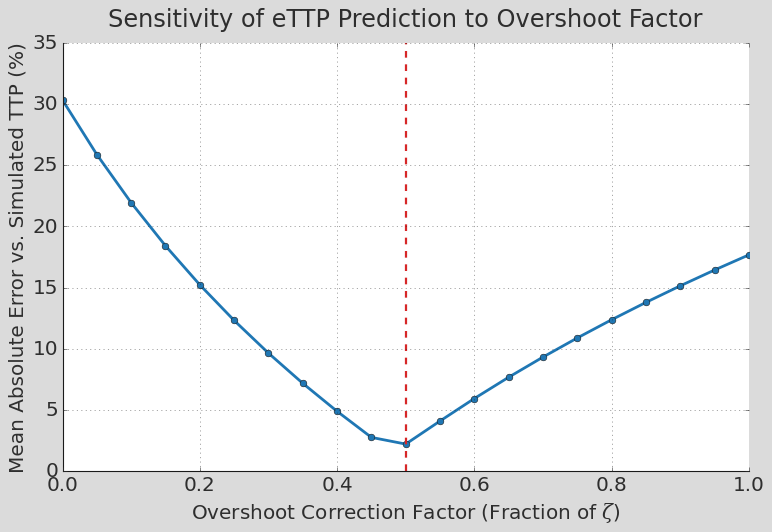

In [41]:
# --- Plotting the Sensitivity Curve ---
plt.rcParams['font.size'] = 18
plt.figure(figsize=(10, 7))

# Plot the error curve
plt.plot(zeta_fractions, mean_absolute_errors, marker='o', linewidth=2.5, color='#1f77b4')

# Highlight the current heuristic
plt.axvline(x=0.5, color='#d62728', linestyle='--', linewidth=2, label='Current Heuristic ($\zeta/2$)')

plt.xlabel(r'Overshoot Correction Factor (Fraction of $\zeta$)')
plt.ylabel('Mean Absolute Error vs. Simulated TTP (%)')
plt.title('Sensitivity of eTTP Prediction to Overshoot Factor', pad=15)
# plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.tight_layout()
# plt.savefig("figures/SI_zeta_sensitivity.pdf", dpi=300)
plt.show()

In [40]:

# Convert lists to numpy arrays for easy slicing
fractions_array = np.array(zeta_fractions)
mae_array = np.array(mean_absolute_errors)

# 1. Find the minimum MAE (which occurs at 0.5)
# Using np.isclose to avoid floating point precision issues
min_idx = np.where(np.isclose(fractions_array, 0.5))[0][0]
min_mae = mae_array[min_idx]

# 2. Evaluate the variation in MAE between 0.3 and 0.7
# Create a boolean mask for the range [0.3, 0.7]
range_mask = (fractions_array >= 0.29) & (fractions_array <= 0.71)
mae_in_range = mae_array[range_mask]

max_mae_in_range = np.max(mae_in_range)
max_error_diff = max_mae_in_range - min_mae

print("--- Sensitivity Analysis Results ---")
print(f"Minimum MAE (at exactly 0.5): {min_mae:.2f}%")
print(f"Maximum MAE within the [0.3, 0.7] range: {max_mae_in_range:.2f}%")
print(f"Maximum variation from minimum error: {max_error_diff:.2f} percentage points")

--- Sensitivity Analysis Results ---
Minimum MAE (at exactly 0.5): 2.20%
Maximum MAE within the [0.3, 0.7] range: 9.64%
Maximum variation from minimum error: 7.44 percentage points
